# Alzheimer Detection: CNN and Attention MIL

Predict **Non Demented (0)** or **Demented (1)** using all MRI images belonging to one patient.
This notebook contains preprocessing, CNN pretraining, attention MIL, five-fold hyperparameter
selection, final training and evaluation. The saved model and results are loaded on later runs.

In [1]:
import json
import itertools
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, log_loss,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
)

print('TensorFlow:', tf.__version__)
print('GPU available:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow: 2.10.0
GPU available: True


## 1. Dataset and settings

Set `binary_path` to the folder containing **Non Demented** and **Demented**.
The patient identifier is the first two filename components, for example `OAS1_0001`.
`save_dir` is the folder used for checkpoints, features and results.
Keep the same `save_dir` to reuse the saved experiment. Choose a different folder to train from scratch.


In [2]:
binary_path = r"data/Alzheimer_Binary"
class_names = ['Non Demented', 'Demented']
i_size, b_size = (124, 248), 32
dropout_values = [0.0, 0.1, 0.3]
learning_rates = [0.0003, 0.001]
configurations = list(itertools.product(dropout_values, learning_rates))

save_dir = Path('alzheimer_saved')
save_dir.mkdir(exist_ok=True)

def reset_seed(seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

def save_json(path, values):
    Path(path).write_text(json.dumps(values, indent=2), encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

reset_seed(42)


In [3]:
image_paths, image_labels, patient_ids = [], [], []

for label, class_name in enumerate(class_names):
    class_path = Path(binary_path) / class_name
    for path in sorted(class_path.iterdir()):
        if path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            image_paths.append(str(path))
            image_labels.append(label)
            patient_ids.append('_'.join(path.name.split('_')[:2]))

image_paths = np.array(image_paths)
image_labels = np.array(image_labels, dtype=np.int32)
patient_ids = np.array(patient_ids)
patients = np.unique(patient_ids)

bags = np.empty(len(patients), dtype=object)
labels = []
for i, patient in enumerate(patients):
    mask = patient_ids == patient
    patient_labels = np.unique(image_labels[mask])
    assert len(patient_labels) == 1, f'Conflicting labels: {patient}'
    bags[i] = image_paths[mask].tolist()
    labels.append(patient_labels[0])
labels = np.array(labels, dtype=np.int32)

print('Total images:', len(image_paths))
print('Total patients:', len(patients))

Total images: 86437
Total patients: 347


## 2. Original image sizes and patient splits

All source image headers are checked once, with the check saved for reruns.
The source images are height **248 x width 496**. Resizing to **124 x 248** halves both
dimensions and preserves the aspect ratio. All images from a patient stay in the same split.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(bags, labels, groups=patients))
X_train, X_test = bags[train_idx], bags[test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]
patients_train, patients_test = patients[train_idx], patients[test_idx]
assert set(patients_train).isdisjoint(patients_test)

# Reuse a saved run only with the same patients, labels and training settings.
data_info = {
    'patients': patients.tolist(), 'labels': labels.tolist(),
    'image_counts': [len(bag) for bag in bags], 'image_size': list(i_size),
    'dropout_values': dropout_values, 'learning_rates': learning_rates,
}
info_path = save_dir / 'data_info.json'
if info_path.exists():
    assert read_json(info_path) == data_info, 'Use a different save_dir for changed data or settings.'
else:
    save_json(info_path, data_info)

size_path = save_dir / 'image_sizes.json'
if size_path.exists():
    sizes = read_json(size_path)
else:
    sizes = Counter()
    for path in image_paths:
        with Image.open(path) as image:
            sizes[f'{image.height} x {image.width}'] += 1
    save_json(size_path, dict(sizes))
assert sizes == {'248 x 496': len(image_paths)}
print('Original image sizes:', dict(sizes))

display(pd.DataFrame({
    'Split': ['Train', 'Test'], 'Patients': [len(y_train), len(y_test)],
    'Non Demented': [int(np.sum(y_train == 0)), int(np.sum(y_test == 0))],
    'Demented': [int(np.sum(y_train == 1)), int(np.sum(y_test == 1))],
}).set_index('Split'))

Original image sizes: {'248 x 496': 86437}


,Patients,Non Demented,Demented
Split,,,
Train,277,210,67
Test,70,56,14


## 3. Preprocessing and datasets

Each image is decoded as grayscale, resized with antialiasing and standardized using its own
mean and standard deviation. The denominator has a floor for nearly constant images.
There is no data augmentation.

```text
standardized pixel = (pixel - image mean) / max(image standard deviation, 1 / sqrt(number of pixels))
```

Image batches train the CNN. Feature bags train attention and the MLP. Complete image bags
are used for patient-level predictions. Patient bags have batch size 1 so their lengths can vary.

In [5]:
def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=1, expand_animations=False)
    image.set_shape((None, None, 1))
    image = tf.image.resize(tf.cast(image, tf.float32), i_size, antialias=True)
    image = tf.image.per_image_standardization(image)
    image.set_shape((*i_size, 1))
    return image, label

def get_class_weights(labels):
    return {c: len(labels) / (2 * np.sum(labels == c)) for c in [0, 1]}

def image_dataset(bags, labels, training=False, weighted=False):
    counts = np.array([len(bag) for bag in bags])
    paths = np.concatenate(bags)
    targets = np.repeat(labels, counts)
    if weighted:
        class_weights = get_class_weights(labels)
        weights = np.concatenate([
            np.full(n, len(paths) / (len(bags) * n) * class_weights[int(y)], np.float32)
            for n, y in zip(counts, labels)
        ])
        ds = tf.data.Dataset.from_tensor_slices((paths, targets, weights))
        def load(path, label, weight):
            image, label = load_image(path, label)
            return image, label, weight
    else:
        ds = tf.data.Dataset.from_tensor_slices((paths, targets))
        load = load_image
    if training:
        ds = ds.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)
    return ds.map(load, num_parallel_calls=4).batch(b_size).prefetch(2), counts

def feature_dataset(features, labels, training=False):
    def generate():
        for features_patient, label in zip(features, labels):
            yield features_patient.astype(np.float32), np.int32(label)
    ds = tf.data.Dataset.from_generator(generate, output_signature=(
        tf.TensorSpec((None, 128), tf.float32), tf.TensorSpec((), tf.int32)))
    if training:
        ds = ds.shuffle(len(labels), seed=42, reshuffle_each_iteration=True)
    return ds.batch(1).prefetch(1)

def make_dataset(bags, labels):
    ds = tf.data.Dataset.from_tensor_slices((tf.ragged.constant(bags.tolist(), dtype=tf.string), labels))
    def load_patient(paths, label):
        images = tf.map_fn(lambda path: load_image(path, label)[0], paths,
                           fn_output_signature=tf.TensorSpec((*i_size, 1), tf.float32))
        return images, label
    return ds.map(load_patient, num_parallel_calls=1).batch(1).prefetch(1)

train_ds = make_dataset(X_train, y_train)
test_ds = make_dataset(X_test, y_test)

## 4. CNN encoder and patient-level model

The shared CNN uses **32, 64 and 128 filters**, with 3 x 3 kernels, ReLU and max pooling.
Global average pooling produces **128 features per image**.

In [6]:
def build_encoder():
    return models.Sequential([
        layers.Input(shape=(*i_size, 1)),
        layers.Conv2D(32, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
    ], name='image_encoder')

def build_image_classifier(encoder):
    inputs = layers.Input(shape=(*i_size, 1))
    x = layers.Dense(64, activation='relu')(encoder(inputs))
    x = layers.Dropout(0.3, seed=42)(x)
    classifier = models.Model(inputs, layers.Dense(1, activation='sigmoid')(x))
    classifier.compile(optimizer=tf.keras.optimizers.Adam(3e-4), loss='binary_crossentropy')
    return classifier

Gated attention learns one score per image using tanh and sigmoid branches. Softmax turns
the scores into weights that sum to one within the patient. The weighted sum of image vectors
is passed through **Dense 64, ReLU, dropout and a sigmoid output**.

```text
patient vector = weight_1 * image vector_1 + ... + weight_m * image vector_m
```

`TimeDistributed` applies the same CNN to every image. The complete model returns one score per patient.

In [7]:
def build_head(dropout_rate, learning_rate):
    inputs = layers.Input(shape=(None, 128), name='image_vectors')
    tanh = layers.Dense(64, activation='tanh', name='attention_tanh')(inputs)
    gate = layers.Dense(64, activation='sigmoid', name='attention_gate')(inputs)
    x = layers.Multiply()([tanh, gate])
    scores = layers.Dense(1, name='attention_scores')(x)
    weights = layers.Softmax(axis=1, name='attention_weights')(scores)
    weights = layers.Permute((2, 1))(weights)
    patient = layers.Dot(axes=(2, 1), name='mil_pooling')([weights, inputs])
    patient = layers.Reshape((128,))(patient)
    x = layers.Dense(64, activation='relu', name='patient_dense')(patient)
    x = layers.Dropout(dropout_rate, seed=42)(x)
    probability = layers.Dense(1, activation='sigmoid', name='patient_probability')(x)
    head = models.Model(inputs, probability, name='attention_mil_head')
    head.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss='binary_crossentropy')
    return head

def build_model(encoder, head):
    encoder.trainable = False
    inputs = layers.Input(shape=(None, *i_size, 1), name='patient_images')
    features = layers.TimeDistributed(encoder, name='shared_cnn')(inputs)
    return models.Model(inputs, head(features), name='patient_attention_mil')

## 5. Exact AUC and callbacks

At each epoch, exact patient ROC AUC selects the checkpoint. During CNN pretraining, image
probabilities are averaged within each patient first. Early stopping and learning-rate reduction
use this same AUC. Epoch histories are saved, with concise fold summaries printed below.

In [8]:
class PatientAUC(tf.keras.callbacks.Callback):
    def __init__(self, val_ds, labels, checkpoint, counts=None):
        super().__init__()
        self.val_ds, self.labels, self.counts = val_ds, labels, counts
        self.checkpoint = checkpoint
        self.best_auc, self.best_epoch, self.history = -np.inf, 0, []

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.val_ds, verbose=0).ravel()
        if self.counts is not None:
            starts = np.r_[0, np.cumsum(self.counts)[:-1]]
            probabilities = np.add.reduceat(probabilities, starts) / self.counts
        auc = float(roc_auc_score(self.labels, probabilities))
        loss = float(log_loss(self.labels, probabilities, labels=[0, 1]))
        logs['val_auc'], logs['val_loss'] = auc, loss
        if auc > self.best_auc + 1e-4:
            self.best_auc, self.best_epoch = auc, epoch + 1
            self.model.save_weights(str(self.checkpoint))
        self.history.append({'epoch': epoch + 1, 'train_loss': float(logs['loss']),
                             'val_auc': auc, 'val_bce': loss})

class MinimumEpochStopping(tf.keras.callbacks.EarlyStopping):
    def __init__(self, minimum_epochs, patience):
        super().__init__(monitor='val_auc', mode='max', min_delta=1e-4, patience=patience)
        self.minimum_epochs = minimum_epochs

    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        if epoch + 1 < self.minimum_epochs:
            self.model.stop_training = False

def create_callbacks(auc_callback):
    early_stopping = MinimumEpochStopping(minimum_epochs=10, patience=8)
    reduce_learning_rate = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc', mode='max', factor=0.5, patience=4, min_lr=1e-5)
    return [auc_callback, early_stopping, reduce_learning_rate]

## 6. CNN pretraining and feature extraction

Pretrain the CNN with a temporary image classifier, Adam learning rate **0.0003** and up to
**6 epochs**. Image weights give patients equal total influence before class balancing.
Restore the best patient-AUC checkpoint and keep its encoder.

Cache the frozen encoder's features so all attention/MLP candidates within a fold reuse them.

In [9]:
def pretrain_encoder(train_bags, train_y, val_bags, val_y, fold_number):
    folder = save_dir / f'fold_{fold_number}'
    folder.mkdir(exist_ok=True)
    encoder_path = folder / 'encoder.h5'
    if encoder_path.exists():
        return encoder_path, read_json(folder / 'encoder_epochs.json')['best_epoch']
    reset_seed(100 + fold_number)
    encoder = build_encoder()
    classifier = build_image_classifier(encoder)
    train_ds, _ = image_dataset(train_bags, train_y, training=True, weighted=True)
    val_ds, counts = image_dataset(val_bags, val_y)
    checkpoint = folder / 'encoder_best.weights.h5'
    auc_callback = PatientAUC(val_ds, val_y, checkpoint, counts)
    classifier.fit(train_ds, epochs=6, callbacks=[auc_callback, MinimumEpochStopping(3, 3)], verbose=0)
    classifier.load_weights(str(checkpoint))
    encoder.save(str(encoder_path), include_optimizer=False)
    save_json(folder / 'encoder_epochs.json', {'best_epoch': auc_callback.best_epoch})
    pd.DataFrame(auc_callback.history).to_csv(folder / 'encoder_history.csv', index=False)
    return encoder_path, auc_callback.best_epoch

def extract_features(encoder_path, bags, labels, cache_path):
    if cache_path.exists():
        with np.load(cache_path) as saved:
            return [saved[f'patient_{i}'] for i in range(len(labels))]
    encoder = models.load_model(str(encoder_path), compile=False)
    image_ds, counts = image_dataset(bags, labels)
    vectors = encoder.predict(image_ds, verbose=0)
    features = list(np.split(vectors, np.cumsum(counts)[:-1]))
    np.savez_compressed(cache_path, **{f'patient_{i}': x for i, x in enumerate(features)})
    return features

## 7. Train one fold and compare hyperparameters

Train attention and the MLP for **10 to 40 epochs**, with patient class weights,
early-stopping patience **8** and learning-rate reduction after **4** epochs without improvement.
The CNN stays frozen. Each fit restores its best checkpoint before calculating train and validation AUC.

In [10]:
def train_one_fold(features_train, train_y, features_val, val_y, dropout_rate, learning_rate, fold_number):
    folder = save_dir / f'fold_{fold_number}' / f'dropout_{dropout_rate:g}_lr_{learning_rate:g}'
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / 'result.json').exists():
        return read_json(folder / 'result.json')
    reset_seed(100 + fold_number)
    head = build_head(dropout_rate, learning_rate)
    train_ds = feature_dataset(features_train, train_y, training=True)
    val_ds = feature_dataset(features_val, val_y)
    checkpoint = folder / 'best.weights.h5'
    auc_callback = PatientAUC(val_ds, val_y, checkpoint)
    head.fit(train_ds, epochs=40, class_weight=get_class_weights(train_y),
             callbacks=create_callbacks(auc_callback), verbose=0)
    head.load_weights(str(checkpoint))
    train_p = head.predict(feature_dataset(features_train, train_y), verbose=0).ravel()
    val_p = head.predict(val_ds, verbose=0).ravel()
    result = {
        'dropout': dropout_rate, 'learning_rate': learning_rate,
        'best_epoch': auc_callback.best_epoch, 'epochs_run': len(auc_callback.history),
        'train_auc': float(roc_auc_score(train_y, train_p)),
        'val_auc': float(roc_auc_score(val_y, val_p)),
        'val_bce': float(log_loss(val_y, val_p, labels=[0, 1])),
    }
    save_json(folder / 'result.json', result)
    pd.DataFrame(auc_callback.history).to_csv(folder / 'history.csv', index=False)
    return result

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_path = save_dir / 'cv_results.csv'

if cv_path.exists():
    results_df = pd.read_csv(cv_path)
    encoder_epochs = read_json(save_dir / 'encoder_epochs.json')
    print('Loaded saved cross-validation results.')
else:
    all_results, encoder_epochs = [], []
    for fold_number, (train_indices, val_indices) in enumerate(
            cv.split(X_train, y_train, groups=patients_train), start=1):
        encoder_path, best_epoch = pretrain_encoder(
            X_train[train_indices], y_train[train_indices], X_train[val_indices], y_train[val_indices], fold_number)
        encoder_epochs.append(best_epoch)
        features = extract_features(encoder_path, X_train, y_train, save_dir / f'fold_{fold_number}' / 'features.npz')
        ft = [features[i] for i in train_indices]
        fv = [features[i] for i in val_indices]
        for dropout_rate, learning_rate in configurations:
            result = train_one_fold(ft, y_train[train_indices], fv, y_train[val_indices],
                                    dropout_rate, learning_rate, fold_number)
            all_results.append({'fold': fold_number, **result})
            print(f'Fold {fold_number}/5 | dropout={dropout_rate:.1f} | LR={learning_rate:.4f}'
                  f' | train AUC={result["train_auc"]:.4f} | val AUC={result["val_auc"]:.4f}'
                  f' | best epoch={result["best_epoch"]}')
    results_df = pd.DataFrame(all_results)
    results_df.to_csv(cv_path, index=False)
    save_json(save_dir / 'encoder_epochs.json', encoder_epochs)

Loaded saved cross-validation results.


Select the highest mean validation AUC across the five folds. Validation loss breaks ties.
The table shows the fold standard deviation, standard error and median best epoch.

In [12]:
rows = []
for (dropout_rate, learning_rate), group in results_df.groupby(['dropout', 'learning_rate']):
    sd = float(group.val_auc.std(ddof=1))
    rows.append({
        'dropout': float(dropout_rate), 'learning_rate': float(learning_rate),
        'train_auc': float(group.train_auc.mean()), 'val_auc': float(group.val_auc.mean()),
        'std': sd, 'se': sd / np.sqrt(5), 'val_loss': float(group.val_bce.mean()),
        'best_epoch': int(np.median(group.best_epoch)),
    })
comparison = pd.DataFrame(rows).sort_values(['val_auc', 'val_loss'], ascending=[False, True])
display(comparison.round(4))
best = comparison.iloc[0]
print(f"Selected: dropout={best['dropout']:.1f}, LR={best['learning_rate']:.4f}, CV AUC={best['val_auc']:.4f}")
chosen = results_df[(results_df.dropout == best['dropout']) & (results_df.learning_rate == best['learning_rate'])]
display(chosen[['fold', 'train_auc', 'val_auc', 'best_epoch', 'epochs_run']].round(4))

Selected: dropout=0.1, LR=0.0010, CV AUC=0.9013


,dropout,learning_rate,train_auc,val_auc,std,se,val_loss,best_epoch
3,0.1,0.0010,0.9199,0.9013,0.0285,0.0127,0.4932,2
1,0.0,0.0010,0.9197,0.9010,0.0290,0.0130,0.4790,2
2,0.1,0.0003,0.9124,0.9009,0.0325,0.0146,0.5197,2
0,0.0,0.0003,0.9130,0.9006,0.0316,0.0141,0.5130,2
4,0.3,0.0003,0.9116,0.9005,0.0314,0.0141,0.5280,3
5,0.3,0.0010,0.9182,0.8988,0.0297,0.0133,0.4619,2


,fold,train_auc,val_auc,best_epoch,epochs_run
3,1,0.9379,0.8864,2,10
9,2,0.9248,0.9374,3,11
15,3,0.9356,0.8700,13,21
21,4,0.8803,0.8878,1,10
27,5,0.9211,0.9249,1,10


## 8. Final training and saved model

Use all training patients and the fold-median epoch counts. Pretrain the CNN, freeze it, and
train the selected attention/MLP head. Save the complete model before evaluating the test patients.
On reruns, load the saved model directly.

In [13]:
model_path = save_dir / 'patient_mil.h5'
pre_epochs = int(np.median(encoder_epochs))
head_epochs = int(best['best_epoch'])

if model_path.exists():
    best_model = models.load_model(str(model_path), compile=False)
    print('Loaded saved model; training skipped.')
else:
    encoder_path = save_dir / 'final_encoder.h5'
    reset_seed(100)
    if not encoder_path.exists():
        encoder = build_encoder()
        classifier = build_image_classifier(encoder)
        pretrain_ds, _ = image_dataset(X_train, y_train, training=True, weighted=True)
        classifier.fit(pretrain_ds, epochs=pre_epochs, verbose=0)
        encoder.save(str(encoder_path), include_optimizer=False)
    reset_seed(100)
    features = extract_features(encoder_path, X_train, y_train, save_dir / 'final_features.npz')
    reset_seed(100)
    head = build_head(float(best['dropout']), float(best['learning_rate']))
    head.fit(feature_dataset(features, y_train, training=True), epochs=head_epochs,
             class_weight=get_class_weights(y_train), verbose=0)
    encoder = models.load_model(str(encoder_path), compile=False)
    best_model = build_model(encoder, head)
    best_model.save(str(model_path), include_optimizer=False)
    best_model = models.load_model(str(model_path), compile=False)

print(f'Final epochs: CNN={pre_epochs}, attention/MLP={head_epochs}')
best_model.summary()

Loaded saved model; training skipped.
Final epochs: CNN=4, attention/MLP=2
Model: "patient_attention_mil"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 patient_images (InputLayer)  [(None, None, 124, 248,   0        
                             1)]                                 
                                                                 
 shared_cnn (TimeDistributed  (None, None, 128)        92672     
 )                                                               
                                                                 
 attention_mil_head (Functio  (None, 1)                24898     
 nal)                                                            
                                                                 
Total params: 117,570
Trainable params: 24,898
Non-trainable params: 92,672
_________________________________________________________________


## 9. Train and test evaluation

Predictions are made once and saved for later runs. ROC AUC measures ranking, while precision,
recall, accuracy and F1 use threshold **0.5**. The observations in every report are patients.

In [14]:
prediction_path = save_dir / 'predictions.npz'
if prediction_path.exists():
    with np.load(prediction_path) as saved:
        train_probabilities, test_probabilities = saved['train'], saved['test']
    print('Loaded saved patient predictions.')
else:
    train_probabilities = best_model.predict(train_ds, verbose=0).ravel()
    test_probabilities = best_model.predict(test_ds, verbose=0).ravel()
    np.savez(prediction_path, train=train_probabilities, test=test_probabilities)

def get_metrics(labels, probabilities):
    predicted = (probabilities >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {
        'AUC': roc_auc_score(labels, probabilities),
        'Average precision': average_precision_score(labels, probabilities),
        'Accuracy': accuracy_score(labels, predicted),
        'Balanced accuracy': balanced_accuracy_score(labels, predicted),
        'Precision': precision_score(labels, predicted, zero_division=0),
        'Recall': recall_score(labels, predicted, zero_division=0),
        'Specificity': tn / (tn + fp), 'F1': f1_score(labels, predicted, zero_division=0),
        'Loss': log_loss(labels, probabilities, labels=[0, 1]),
    }

display(pd.DataFrame({'Train': get_metrics(y_train, train_probabilities),
                      'Test': get_metrics(y_test, test_probabilities)}).round(4))

Loaded saved patient predictions.


,Train,Test
AUC,0.9260,0.9362
Average precision,0.7377,0.8324
Accuracy,0.8195,0.8857
Balanced accuracy,0.8606,0.8750
Precision,0.5780,0.6667
Recall,0.9403,0.8571
Specificity,0.7810,0.8929
F1,0.7159,0.7500
Loss,0.4717,0.4182


The ROC plot and confusion matrices summarize the test ranking and threshold-based decisions.
The AUC interval uses 2,000 stratified patient bootstrap samples, with seed 42.

Test AUC 95% bootstrap interval: [0.8686, 0.9847]


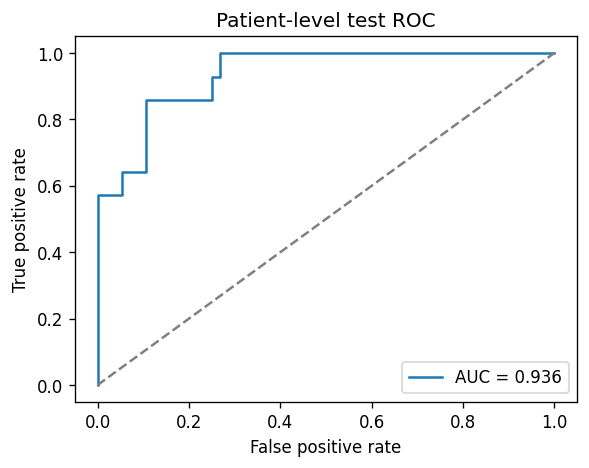

In [15]:
interval_path = save_dir / 'auc_interval.json'
if interval_path.exists():
    low, high = read_json(interval_path)
else:
    rng = np.random.default_rng(42)
    class_indices = [np.flatnonzero(y_test == c) for c in [0, 1]]
    bootstrap_auc = []
    for _ in range(2000):
        sample = np.concatenate([rng.choice(idx, len(idx), replace=True) for idx in class_indices])
        bootstrap_auc.append(roc_auc_score(y_test[sample], test_probabilities[sample]))
    low, high = np.quantile(bootstrap_auc, [0.025, 0.975]).tolist()
    save_json(interval_path, [low, high])
print(f'Test AUC 95% bootstrap interval: [{low:.4f}, {high:.4f}]')

fpr, tpr, _ = roc_curve(y_test, test_probabilities)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, test_probabilities):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Patient-level test ROC')
plt.legend()
plt.tight_layout()
plt.show()

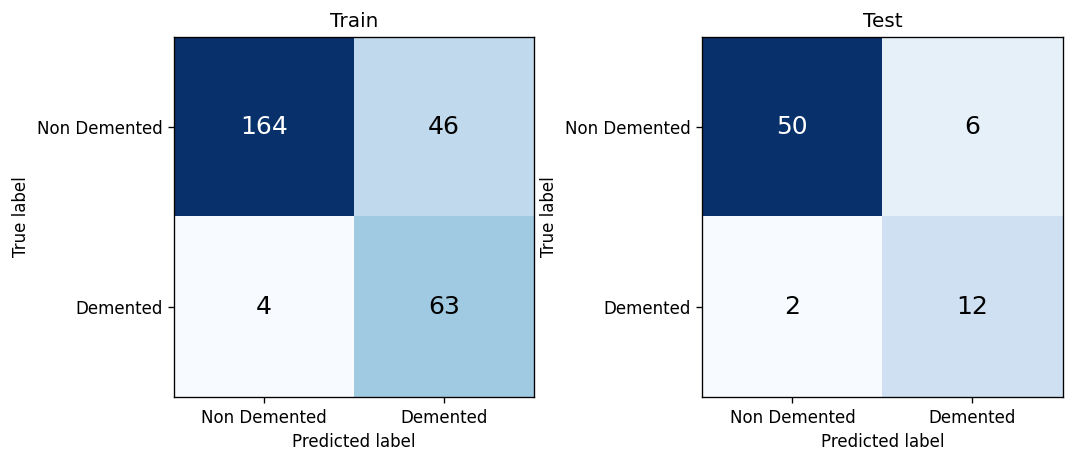

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name, y, probabilities in zip(axes, ['Train', 'Test'], [y_train, y_test],
                                     [train_probabilities, test_probabilities]):
    matrix = confusion_matrix(y, probabilities >= 0.5, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for (row, column), value in np.ndenumerate(matrix):
        ax.text(column, row, str(value), ha='center', va='center', fontsize=15,
                color='white' if value > matrix.max() / 2 else 'black')
    ax.set_xticks([0, 1], class_names)
    ax.set_yticks([0, 1], class_names)
    ax.set(xlabel='Predicted label', ylabel='True label', title=name)
plt.tight_layout()
plt.show()

## 10. Classification reports

`support` is the number of patients. The training report describes patients used to fit the model.
Both reports use threshold **0.5**.

In [17]:
print('TRAIN | threshold 0.5')
print(classification_report(y_train, train_probabilities >= 0.5,
                            target_names=class_names, digits=3, zero_division=0))
print('TEST | threshold 0.5')
print(classification_report(y_test, test_probabilities >= 0.5,
                            target_names=class_names, digits=3, zero_division=0))

TRAIN | threshold 0.5
              precision    recall  f1-score   support

Non Demented      0.976     0.781     0.868       210
    Demented      0.578     0.940     0.716        67

    accuracy                          0.819       277
   macro avg      0.777     0.861     0.792       277
weighted avg      0.880     0.819     0.831       277

TEST | threshold 0.5
              precision    recall  f1-score   support

Non Demented      0.962     0.893     0.926        56
    Demented      0.667     0.857     0.750        14

    accuracy                          0.886        70
   macro avg      0.814     0.875     0.838        70
weighted avg      0.903     0.886     0.891        70

